Section 1:
In chemical engineering curriculum and industrial operations, evaluating shell and tube heat exchangers, such as during unit operations lab experiments utilizing water-water streams, requires repetitive thermodynamic modeling. Students and practicing engineers often spend hours performing tedious hand calculations or manually coding complex effectiveness and LMTD formulas into spreadsheets. Based on firsthand observational data from undergraduate unit operations lab coursework, students spend up to 4 to 6 hours constructing spreadsheets for single heat exchanger runs before meaningful data analysis or trend evaluation can begin. This creates a significant bottleneck, diverting valuable time away from higher-level engineering tasks like parameter correlation, troubleshooting, and design optimization.   To address this challenge, the Shell and Tube Heat Exchanger Simulation App provides an intuitive graphical interface for instant performance modeling. By integrating direct temperature overlays, flow pattern selection (cocurrent and countercurrent), and automated energy balances, the app allows users to compute overall heat transfer coefficients (U), heat duty (Q), LMTD, and effectiveness (e) in seconds. For undergraduate students, it transforms hours of repetitive calculation into rapid data analysis. For industry professionals, it offers a quick mechanism to "pressure test" operating conditions and assess thermal performance under strict plant constraints, such as cooling water return limits.

Value Proposition:
For Chemical Engineering students taking the Unit Operations Lab, who must process experimental heat exchanger data through multi-step thermodynamic calculations, my app is an automated desktop calculator built for the Armfield HT33 Shell & Tube Exchanger. Unlike manually building complex formulas in Excel or performing repetitive hand calculations, my app instantly computes LMTD, heat transfer rates, U-coefficients, and efficiency with built-in input validation—eliminating calculation errors and saving valuable time for data analysis. 
My app is unique because it will also have a temperature profile feature that displays a graph of the temperature profile across the length of the exchanger. Also, my GUI will have physical and thermodynamic constraints so that the user can avoid using negligible data. 


Engineering Principles and Equations:
My code revolves around the equations that apply to a shell and tube heat exchanger. Those calculations are 
Q= Hot stream capacity * (deltaT)
Hot stream capacity rates = mass flow(hot) * heat capacity(hot)
Cold stream capacity rates = mass flow(cold) * heat capacity(cold)
Capacity Ratio = Cmin/Cmax
LMTD = (deltaT1-deltaT2)/ln(deltaT1/deltaT2)
U = Q/A*LMTD
NTU = U*A/Cmin
Countercurrent effectiveness = (1-e^(-NTU(1-Cr)))/(1-Cr*e^(-NTU(1-Cr)))
Countercurrent effectiveness = NTU/1+NTU
Cocurrent effectiveness = (1-e^(-NTU(1+Cr)))/(1+Cr)

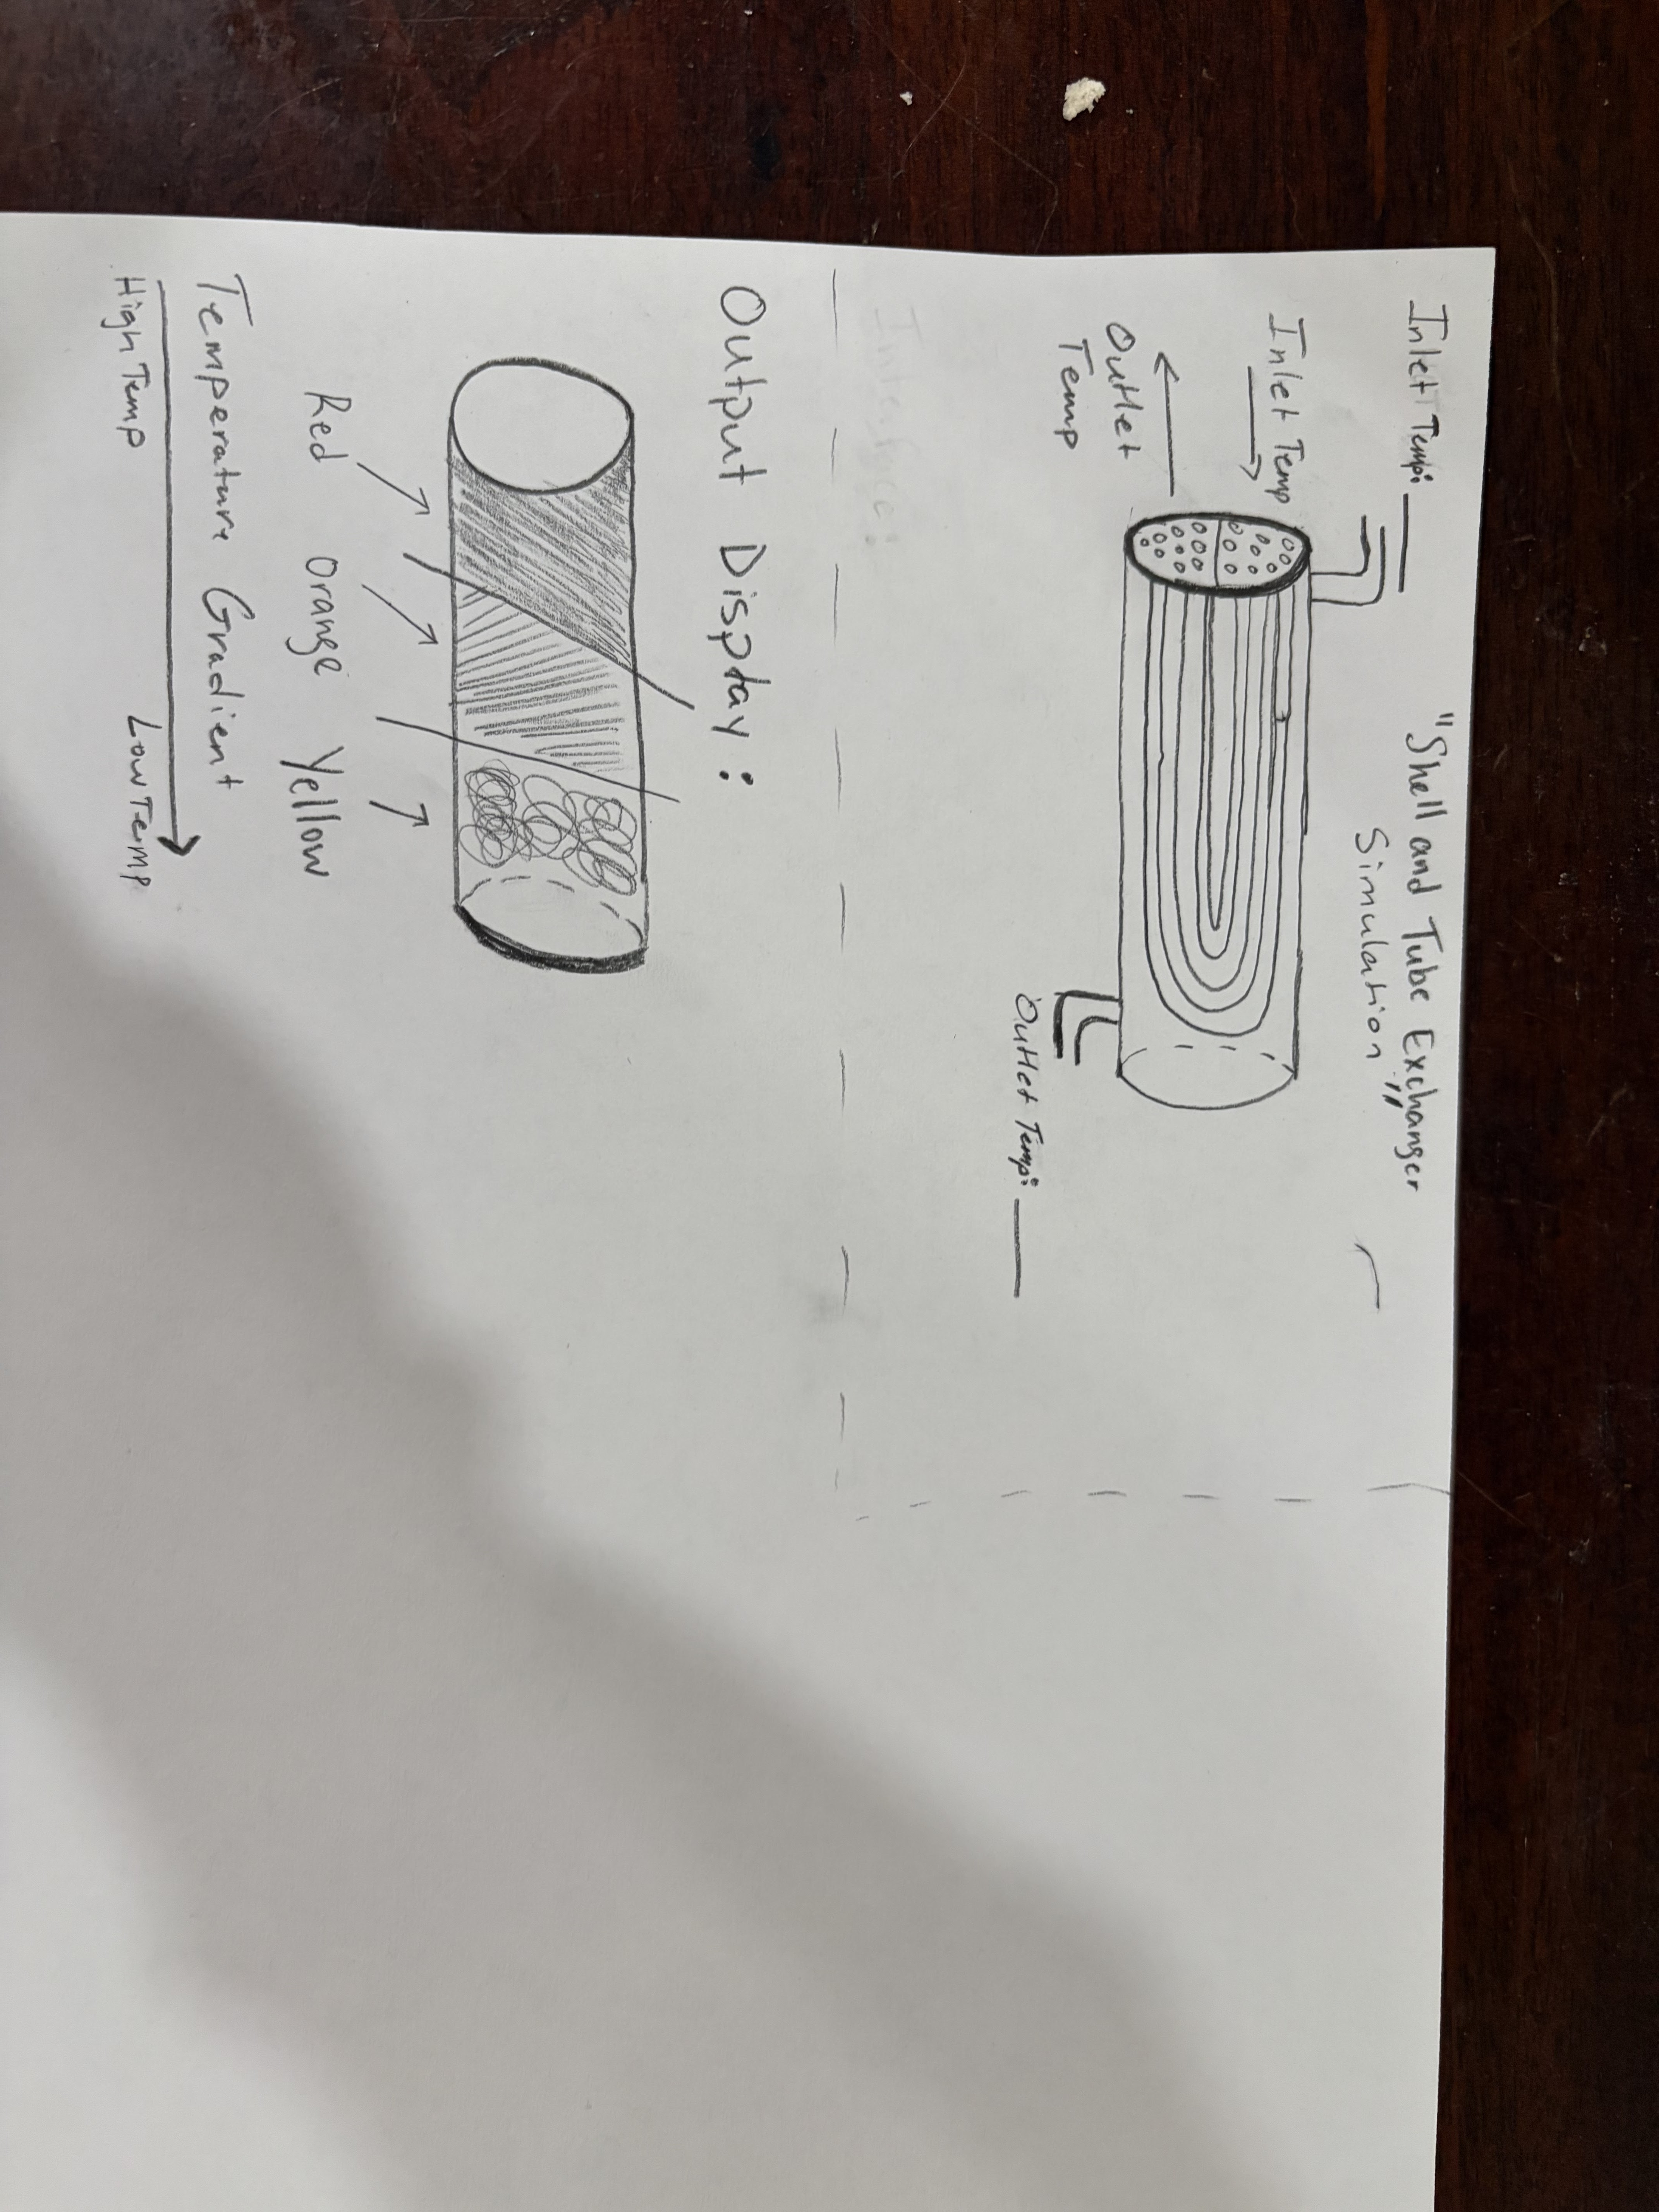

In [25]:
from IPython.display import Image, display

display(Image(filename='shell.and.tube.image.jpg'))

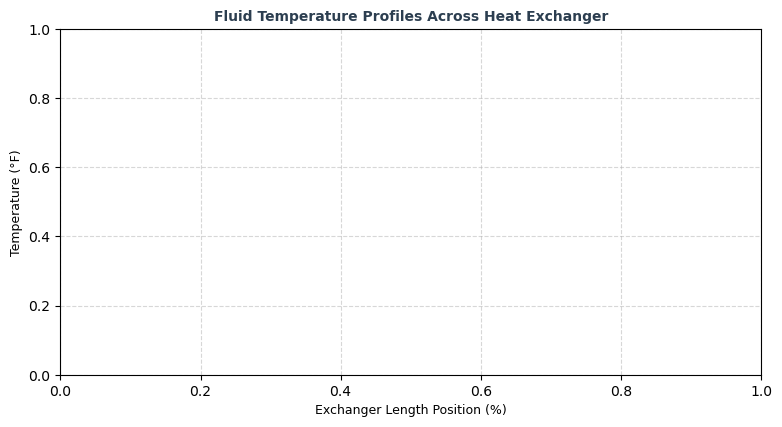

In [7]:
import math
import tkinter as tk
from tkinter import messagebox, ttk
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
import matplotlib.pyplot as plt


class ShellTubeExchangerGUI:

  def __init__(self, root):
    self.root = root
    self.root.title("Shell and Tube Exchanger Simulation (Water System)")
    self.root.geometry("1150x950")
    self.root.configure(bg="#f4f6f7")

    self.setup_ui()

  def setup_ui(self):
    title = tk.Label(
        self.root,
        text="Shell and Tube Exchanger Simulation (Water System)",
        font=("Helvetica", 18, "bold"),
        bg="#f4f6f7",
        fg="#2c3e50",
    )
    title.pack(pady=(10, 5))

    main_frame = tk.Frame(self.root, bg="#f4f6f7")
    main_frame.pack(fill=tk.BOTH, expand=True, padx=15, pady=5)

    # Control Bar
    control_bar = tk.Frame(
        main_frame, bg="#ffffff", bd=1, relief=tk.SOLID, padx=10, pady=8
    )
    control_bar.pack(fill=tk.X, pady=(0, 10))

    tk.Label(
        control_bar,
        text="Known Parameters:",
        font=("Helvetica", 10, "bold"),
        bg="#ffffff",
    ).grid(row=0, column=0, padx=5, sticky="w")
    self.input_mode = tk.StringVar(value="tube")

    rb_tube = tk.Radiobutton(
        control_bar,
        text="Enter Hot Water Temps (Solve Cooling)",
        variable=self.input_mode,
        value="tube",
        command=self.update_mode,
        bg="#ffffff",
    )
    rb_tube.grid(row=0, column=1, padx=10, sticky="w")

    rb_shell = tk.Radiobutton(
        control_bar,
        text="Enter Cooling Water Temps (Solve Hot)",
        variable=self.input_mode,
        value="shell",
        command=self.update_mode,
        bg="#ffffff",
    )
    rb_shell.grid(row=0, column=2, padx=10, sticky="w")

    tk.Label(
        control_bar,
        text="Flow Configuration:",
        font=("Helvetica", 10, "bold"),
        bg="#ffffff",
    ).grid(row=0, column=3, padx=(20, 5), sticky="w")
    self.flow_pattern = tk.StringVar(value="countercurrent")

    rb_counter = tk.Radiobutton(
        control_bar,
        text="Countercurrent",
        variable=self.flow_pattern,
        value="countercurrent",
        command=self.draw_interactive_diagram,
        bg="#ffffff",
    )
    rb_counter.grid(row=0, column=4, padx=5)

    rb_co = tk.Radiobutton(
        control_bar,
        text="Cocurrent",
        variable=self.flow_pattern,
        value="cocurrent",
        command=self.draw_interactive_diagram,
        bg="#ffffff",
    )
    rb_co.grid(row=0, column=5, padx=5)

    # Mass Flow Inputs
    tk.Label(
        control_bar,
        text="Hot Water Flow Rate (m_h, lb/h):",
        font=("Helvetica", 10, "bold"),
        bg="#ffffff",
    ).grid(row=1, column=0, padx=5, pady=(8, 0), sticky="w")
    self.entry_m_tube = tk.Entry(
        control_bar, width=10, font=("Courier", 10, "bold"), justify="center"
    )
    self.entry_m_tube.insert(0, "15000.0")
    self.entry_m_tube.grid(row=1, column=1, padx=10, pady=(8, 0), sticky="w")

    tk.Label(
        control_bar,
        text="Cooling Water Flow Rate (m_c, lb/h):",
        font=("Helvetica", 10, "bold"),
        bg="#ffffff",
    ).grid(row=1, column=2, padx=(20, 5), pady=(8, 0), sticky="w")
    self.entry_m_shell = tk.Entry(
        control_bar, width=10, font=("Courier", 10, "bold"), justify="center"
    )
    self.entry_m_shell.insert(0, "20000.0")
    self.entry_m_shell.grid(row=1, column=3, padx=5, pady=(8, 0), sticky="w")

    # Diagram Canvas Group
    top_group = tk.LabelFrame(
        main_frame,
        text=" Interactive Shell and Tube Input Diagram ",
        font=("Helvetica", 11, "bold"),
        bg="#ffffff",
        padx=10,
        pady=5,
    )
    top_group.pack(fill=tk.BOTH, expand=False, pady=(0, 10))

    self.canvas_input = tk.Canvas(
        top_group, bg="#ffffff", height=240, highlightthickness=0
    )
    self.canvas_input.pack(fill=tk.BOTH, expand=True)

    self.entry_shell_in = tk.Entry(
        self.canvas_input,
        width=7,
        font=("Courier", 10, "bold"),
        justify="center",
    )
    self.entry_shell_in.insert(0, "95.0")

    self.entry_shell_out = tk.Entry(
        self.canvas_input,
        width=7,
        font=("Courier", 10, "bold"),
        justify="center",
    )
    self.entry_shell_out.insert(0, "110.0")

    self.entry_tube_in = tk.Entry(
        self.canvas_input,
        width=7,
        font=("Courier", 10, "bold"),
        justify="center",
    )
    self.entry_tube_in.insert(0, "180.0")

    self.entry_tube_out = tk.Entry(
        self.canvas_input,
        width=7,
        font=("Courier", 10, "bold"),
        justify="center",
    )
    self.entry_tube_out.insert(0, "160.0")

    self.btn_run = tk.Button(
        top_group,
        text="Run Simulation & Render Gradient",
        command=self.run_simulation,
        bg="#27ae60",
        fg="white",
        font=("Helvetica", 10, "bold"),
        padx=10,
        pady=4,
    )
    self.btn_run.pack(pady=5)

    # Output Section
    bottom_group = tk.LabelFrame(
        main_frame,
        text=" Simulation Outputs & Temperature Profile ",
        font=("Helvetica", 11, "bold"),
        bg="#ffffff",
        padx=10,
        pady=5,
    )
    bottom_group.pack(fill=tk.BOTH, expand=True)

    out_split = tk.Frame(bottom_group, bg="#ffffff")
    out_split.pack(fill=tk.BOTH, expand=True)

    # Matplotlib Figure Frame
    self.plot_frame = tk.Frame(out_split, bg="#ffffff")
    self.plot_frame.pack(side=tk.LEFT, fill=tk.BOTH, expand=True)

    self.fig, self.ax = plt.subplots(figsize=(6, 3.2), dpi=100)
    self.fig.patch.set_facecolor("#ffffff")
    self.plot_canvas = FigureCanvasTkAgg(self.fig, master=self.plot_frame)
    self.plot_canvas.get_tk_widget().pack(fill=tk.BOTH, expand=True)

    results_box = tk.Frame(
        out_split, bg="#f8f9f9", bd=1, relief=tk.SOLID, padx=15, pady=15
    )
    results_box.pack(side=tk.RIGHT, fill=tk.Y, padx=(10, 0))

    tk.Label(
        results_box,
        text="Calculated Outputs",
        font=("Helvetica", 11, "bold"),
        bg="#f8f9f8",
        fg="#2c3e50",
    ).pack(anchor="w", pady=(0, 10))

    self.lbl_duty = tk.Label(
        results_box,
        text="Heat Duty (Q): -- BTU/hr",
        font=("Helvetica", 10),
        bg="#f8f9f9",
        fg="#2c3e50",
    )
    self.lbl_duty.pack(anchor="w", pady=4)

    self.lbl_lmtd = tk.Label(
        results_box,
        text="LMTD (ΔT_lm): -- °F",
        font=("Helvetica", 10),
        bg="#f8f9f9",
        fg="#2c3e50",
    )
    self.lbl_lmtd.pack(anchor="w", pady=4)

    self.lbl_U_calc = tk.Label(
        results_box,
        text="Overall U: -- BTU/hr·ft²·°F",
        font=("Helvetica", 10),
        bg="#f8f9f9",
        fg="#2c3e50",
    )
    self.lbl_U_calc.pack(anchor="w", pady=4)

    self.lbl_eff = tk.Label(
        results_box,
        text="Effectiveness (ε): -- %",
        font=("Helvetica", 10),
        bg="#f8f9f9",
        fg="#2c3e50",
    )
    self.lbl_eff.pack(anchor="w", pady=4)

    self.update_mode()

  def update_mode(self):
    mode = self.input_mode.get()
    if mode == "tube":
      self.entry_tube_in.config(state="normal", bg="#ffffff")
      self.entry_tube_out.config(state="normal", bg="#ffffff")
      self.entry_shell_in.config(
          state="disabled", disabledbackground="#eaeded"
      )
      self.entry_shell_out.config(
          state="disabled", disabledbackground="#eaeded"
      )
    else:
      self.entry_shell_in.config(
          state="disabled", disabledbackground="#eaeded"
      )
      self.entry_shell_out.config(state="normal", bg="#ffffff")
      self.entry_tube_in.config(
          state="disabled", disabledbackground="#eaeded"
      )
      self.entry_tube_out.config(
          state="disabled", disabledbackground="#eaeded"
      )

    self.entry_shell_in.config(state="normal")
    self.entry_shell_in.delete(0, tk.END)
    self.entry_shell_in.insert(0, "95.0")
    self.entry_shell_in.config(state="disabled")

    self.draw_interactive_diagram()
    self.plot_initial_graph()

  def draw_interactive_diagram(self):
    c = self.canvas_input
    c.delete("all")

    pattern = self.flow_pattern.get()

    c.create_rectangle(
        200, 40, 700, 180, outline="#2c3e50", width=3, fill="#f8f9f9"
    )
    c.create_oval(660, 40, 740, 180, outline="#2c3e50", width=3, fill="#ebedef")
    c.create_rectangle(
        185, 30, 200, 190, fill="#7f8c8d", outline="#2c3e50", width=2
    )

    for offset in [0, 20, 40, 60]:
      c.create_line(
          200,
          70 + offset / 2,
          650 - offset,
          70 + offset / 2,
          fill="#e74c3c",
          width=3,
      )
      c.create_line(
          200,
          150 - offset / 2,
          650 - offset,
          150 - offset / 2,
          fill="#e74c3c",
          width=3,
      )
      c.create_arc(
          610 - offset,
          70 + offset / 2,
          690 - offset,
          150 - offset / 2,
          start=-90,
          extent=180,
          style=tk.ARC,
          outline="#e74c3c",
          width=3,
      )

    c.create_rectangle(
        290, 10, 320, 40, fill="#3498db", outline="#2980b9", width=2
    )

    if pattern == "countercurrent":
      c.create_rectangle(
          630, 180, 660, 210, fill="#3498db", outline="#2980b9", width=2
      )
      shell_out_pos = (645, 215)
    else:
      c.create_rectangle(
          290, 180, 320, 210, fill="#3498db", outline="#2980b9", width=2
      )
      shell_out_pos = (305, 215)

    c.create_window(305, 10, window=self.entry_shell_in)
    c.create_text(
        220,
        10,
        text="Inlet Temp (°F):",
        font=("Helvetica", 9, "bold"),
        fill="#2980b9",
    )

    c.create_window(
        shell_out_pos[0], shell_out_pos[1], window=self.entry_shell_out
    )
    c.create_text(
        shell_out_pos[0] - 80,
        shell_out_pos[1],
        text="Outlet Temp (°F):",
        font=("Helvetica", 9, "bold"),
        fill="#16a085",
    )

    c.create_line(110, 70, 190, 70, arrow=tk.LAST, width=3, fill="#c0392b")
    c.create_window(50, 70, window=self.entry_tube_in)
    c.create_text(
        50, 48, text="Inlet Temp (°F)", font=("Helvetica", 9, "bold"), fill="#c0392b"
    )

    c.create_line(190, 150, 110, 150, arrow=tk.LAST, width=3, fill="#d35400")
    c.create_window(50, 150, window=self.entry_tube_out)
    c.create_text(
        50,
        172,
        text="Outlet Temp (°F)",
        font=("Helvetica", 9, "bold"),
        fill="#d35400",
    )

  def plot_initial_graph(self):
    self.ax.clear()
    self.ax.set_title(
        "Fluid Temperature Profiles Across Heat Exchanger",
        fontsize=10,
        fontweight="bold",
        color="#2c3e50",
    )
    self.ax.set_xlabel("Exchanger Length Position (%)", fontsize=9)
    self.ax.set_ylabel("Temperature (°F)", fontsize=9)
    self.ax.grid(True, linestyle="--", alpha=0.5)
    self.plot_canvas.draw()

  def update_temperature_plot(
      self, Th_in, Th_out, Tc_in, Tc_out, pattern, C_h, C_c
  ):
    self.ax.clear()

    steps = 100
    x = [i / steps * 100 for i in range(steps + 1)]

    dT1 = Th_in - Tc_out if pattern == "countercurrent" else Th_in - Tc_in
    dT2 = Th_out - Tc_in if pattern == "countercurrent" else Th_out - Tc_out

    T_hot = []
    T_cold = []

    if pattern == "cocurrent":
      for i in range(steps + 1):
        pos = i / steps
        dT_x = dT1 * math.exp(
            math.log(dT2 / dT1) * pos if dT1 > 0 and dT2 > 0 else 0
        )
        Q_x = (dT1 - dT_x) / ((1.0 / C_h) + (1.0 / C_c))
        T_h_x = Th_in - (Q_x / C_h)
        T_c_x = Tc_in + (Q_x / C_c)
        T_hot.append(T_h_x)
        T_cold.append(T_c_x)
    else:
      for i in range(steps + 1):
        pos = i / steps
        if abs(dT1 - dT2) > 1e-4 and dT1 > 0 and dT2 > 0:
          dT_x = dT1 * math.exp(math.log(dT2 / dT1) * pos)
        else:
          dT_x = dT1

        if C_h != C_c:
          Q_x = (dT1 - dT_x) / ((1.0 / C_h) - (1.0 / C_c))
        else:
          Q_x = (C_h * (Th_in - Th_out)) * pos

        T_h_x = Th_in - (Q_x / C_h)
        T_c_x = Tc_out - (Q_x / C_c)
        T_hot.append(T_h_x)
        T_cold.append(T_c_x)

    self.ax.plot(
        x, T_hot, color="#c0392b", linewidth=2.5, label="Hot Water Stream"
    )
    self.ax.plot(
        x, T_cold, color="#2980b9", linewidth=2.5, label="Cooling Water Stream"
    )

    self.ax.set_title(
        f"Temperature Profile ({pattern.capitalize()} Flow)",
        fontsize=10,
        fontweight="bold",
        color="#2c3e50",
    )
    self.ax.set_xlabel("Exchanger Length Position (%)", fontsize=9)
    self.ax.set_ylabel("Temperature (°F)", fontsize=9)
    self.ax.grid(True, linestyle="--", alpha=0.5)
    self.ax.legend(loc="best", fontsize=8)

    self.fig.tight_layout()
    self.plot_canvas.draw()

  def run_simulation(self):
    try:
      mode = self.input_mode.get()
      pattern = self.flow_pattern.get()

      m_h = float(self.entry_m_tube.get())
      m_c = float(self.entry_m_shell.get())

      if m_h <= 0 or m_c <= 0:
        raise ValueError("Mass flow rates must be positive numbers.")

      cph = 1.0
      cpc = 1.0
      A = 130.0
      U_assumed = 150.0

      Tc_in = 95.0

      if mode == "tube":
        Th_in = float(self.entry_tube_in.get())
        Th_out = float(self.entry_tube_out.get())

        if Th_out >= Th_in:
          raise ValueError(
              "Hot water outlet temperature must be lower than inlet"
              " temperature."
          )

        C_h = m_h * cph
        C_c = m_c * cpc

        Q = C_h * (Th_in - Th_out)
        Tc_out = Tc_in + (Q / C_c)

        if Tc_out > 120.0:
          raise ValueError(
              f"Cooling water return temperature ({Tc_out:.2f}°F) exceeds"
              " maximum allowable limit of 120.0°F."
          )

        self.entry_shell_in.config(state="normal")
        self.entry_shell_in.delete(0, tk.END)
        self.entry_shell_in.insert(0, f"{Tc_in:.1f}")
        self.entry_shell_in.config(state="disabled")

        self.entry_shell_out.config(state="normal")
        self.entry_shell_out.delete(0, tk.END)
        self.entry_shell_out.insert(0, f"{Tc_out:.1f}")
        self.entry_shell_out.config(state="disabled")

      else:
        Tc_out = float(self.entry_shell_out.get())

        if Tc_out > 120.0:
          raise ValueError(
              f"Cooling water return temperature ({Tc_out:.2f}°F) exceeds"
              " maximum allowable limit of 120.0°F."
          )

        if Tc_out <= Tc_in:
          raise ValueError(
              "Cooling water outlet temperature must be higher than inlet"
              " temperature (95.0°F)."
          )

        C_h = m_h * cph
        C_c = m_c * cpc

        Q = C_c * (Tc_out - Tc_in)
        Th_in = 180.0
        Th_out = Th_in - (Q / C_h)

        self.entry_tube_in.config(state="normal")
        self.entry_tube_in.delete(0, tk.END)
        self.entry_tube_in.insert(0, f"{Th_in:.1f}")
        self.entry_tube_in.config(state="disabled")

        self.entry_tube_out.config(state="normal")
        self.entry_tube_out.delete(0, tk.END)
        self.entry_tube_out.insert(0, f"{Th_out:.1f}")
        self.entry_tube_out.config(state="disabled")

      C_min = min(C_h, C_c)
      C_max = max(C_h, C_c)
      C_r = C_min / C_max
      NTU = (U_assumed * A) / C_min

      if pattern == "countercurrent":
        epsilon = (
            (1.0 - math.exp(-NTU * (1.0 - C_r)))
            / (1.0 - C_r * math.exp(-NTU * (1.0 - C_r)))
            if C_r != 1.0
            else NTU / (1.0 + NTU)
        )
      else:
        epsilon = (1.0 - math.exp(-NTU * (1.0 + C_r))) / (1.0 + C_r)

      dT1 = Th_in - Tc_out if pattern == "countercurrent" else Th_in - Tc_in
      dT2 = Th_out - Tc_in if pattern == "countercurrent" else Th_out - Tc_out

      LMTD = (
          (dT1 - dT2) / math.log(dT1 / dT2)
          if abs(dT1 - dT2) > 1e-4 and dT1 > 0 and dT2 > 0
          else dT1
      )
      U_calc = (Q / (A * LMTD)) if (A * LMTD) > 0 else U_assumed

      self.lbl_duty.config(text=f"Heat Duty (Q): {Q:,.0f} BTU/hr")
      self.lbl_lmtd.config(text=f"LMTD (ΔT_lm): {LMTD:.2f} °F")
      self.lbl_U_calc.config(text=f"Overall U: {U_calc:.1f} BTU/hr·ft²·°F")
      self.lbl_eff.config(text=f"Effectiveness (ε): {epsilon * 100:.1f} %")

      self.update_temperature_plot(
          Th_in, Th_out, Tc_in, Tc_out, pattern, C_h, C_c
      )

    except Exception as e:
      messagebox.showerror(
          "Error", f"Failed to compute simulation results.\nDetails: {e}"
      )


if __name__ == "__main__":
  root = tk.Tk()
  app = ShellTubeExchangerGUI(root)
  root.mainloop()

AI Prompting:

Prompt 1: I want to create a simulation of a shell and tube heat exchanger in which the user can insert values the hot and cold temperatures,
and the simulation runs similar to the attached simulation. Also, the user can pick between cocurrent and countercurrent flow patterns and the internal
flows can be seen in the simulation with the cold stream being blue and the hot stream being red. I want the outputs to be overall heat transfer
coefficent (U), LMTD, etc. Create a gui and use tkinter for the construction of the GUI. (This was the original prompt that I gave the AI but I did not have my phone to be able to show via picture what I wanted from the AI)
    
Prompt 2: I also want the user to be able to enter the outlet temperatures and the simulation calculate the inlet temperatures, so try and 
put the input boxes on the simulation itself to make it more user friendly. (I wanted the user to be able to manipulate both streams into the exchanger not jsut one)

Prompt 3: This is the idea that I have of the gui. The display will have a shell and tube heat exchanger with the option to insert two temperatures either shell side temperatures or tube side temperatures. Also, there is an outlet display that is generated from running the app that has a shell temperature gradient that shows the heat map across the shell with red being the hottest part, then orange, then yellow. (This prompt is when I drew my original idea of the GUI design with the output of the temperaature gradient)

Prompt 4: take out the circle and the dots section of the tubes it doesnt look good (cleaning up the look)

Prompt 5: lets change the code so that the user inputs the mass flow rate of both sides. (The AI was assuming too many parameters I wanted to constrain it more )

Prompt 6: lets change the utility to always being cooling water for the first iteration of this simulation. Here are the properties for cooling water that should be used at all times. Also, the user should be able to put the colling water either on the shell side or the tube side. since the cooling water is used as the cooling medium the "Cold side" can now be referred to as "Cooling water" (I felt the AI was assuming too many paramters for the physical properties of the fluids and it was case specific so the user would get worng answers if it was trying to use the same GUI for different types of fluids or gases)

Prompt 7: add that the inlet temperature of the cooling water is always 95 degrees F and the max return temperature of the cooling water is 120 degrees F if the user tries to put a value higher than 120 report an error (I changed the simulation to a water- water exchanger since the lab is a water water exchanger and I used the temperature constraints given in CHEE 407)

Prompt 8: could you also add to the code a graphical display output of the temperature profile that shows the temperature change from runnign the simulation to when it reaches equilibrium. (I did not like the display that the app was giving me it did not make what I wanted exactly so I reverted to change it to a trend of the temperature profile from the initial temperatures to equilibrium)
